### Data Import

In [389]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
import seaborn as sns

In [390]:
project_root = Path().resolve()
data_path = Path(project_root/ "data"/ "df_final.csv")

df_train = pd.read_csv(data_path)

In [391]:
data_path2 = Path(project_root/ "data"/ "df_test.csv")

df_test = pd.read_csv(data_path2)

In [392]:
# Quick NaN check on train/test
print("NaN counts (train):")
print(df_train.isna().sum().sort_values(ascending=False).head(10))
print("\nNaN counts (test):")
print(df_test.isna().sum().sort_values(ascending=False).head(10))

NaN counts (train):
creation_year                             165
montant_engage                              0
forme_juridique_grp_Syndicat                0
demarche_Energie                            0
demarche_Ingenierie                         0
demarche_Mobilites                          0
demarche_Risques_climatiques                0
forme_juridique_grp_Autres                  0
forme_juridique_grp_Commune                 0
forme_juridique_grp_Departement_Region      0
dtype: int64

NaN counts (test):
categorieentreprise_te                53
creation_year                         43
montant_engage                         0
forme_juridique_grp_State_Operator     0
demarche_Energie                       0
demarche_Ingenierie                    0
demarche_Mobilites                     0
demarche_Risques_climatiques           0
forme_juridique_grp_Autres             0
forme_juridique_grp_Commune            0
dtype: int64


In [393]:
X_train = df_train.drop('montant_engage', axis=1)
y_train = df_train['montant_engage']

X_test = df_test.drop('montant_engage', axis=1)
y_test = df_test['montant_engage']

In [394]:
# Check data loading
print("Data Loading Verification:")
print(f"  X_train shape: {X_train.shape}")
print(f"  y_train shape: {y_train.shape}")
print(f"  X_test shape: {X_test.shape}")
print(f"  y_test shape: {y_test.shape}")
print(f"\n  Target statistics:")
print(f"  Train - Min: {y_train.min():,.0f}, Max: {y_train.max():,.0f}, Mean: {y_train.mean():,.0f}")
print(f"  Test  - Min: {y_test.min():,.0f}, Max: {y_test.max():,.0f}, Mean: {y_test.mean():,.0f}")

Data Loading Verification:
  X_train shape: (7094, 48)
  y_train shape: (7094,)
  X_test shape: (1774, 48)
  y_test shape: (1774,)

  Target statistics:
  Train - Min: 288, Max: 11,600,000, Mean: 181,802
  Test  - Min: 425, Max: 8,921,761, Mean: 185,226


In [395]:
# Align train/test feature columns to the common set
train_cols = set(X_train.columns)
test_cols = set(X_test.columns)
common_cols = sorted(train_cols & test_cols)

# Restrict to common columns only (drops any extras)
X_train = X_train[common_cols]
X_test = X_test[common_cols]

print(f"Train columns: {len(train_cols)}, Test columns: {len(test_cols)}, Common: {len(common_cols)}")
missing_train = test_cols - train_cols
missing_test = train_cols - test_cols
if missing_train:
    print("Columns only in test (dropped):", sorted(missing_train))
if missing_test:
    print("Columns only in train (dropped):", sorted(missing_test))

Train columns: 48, Test columns: 48, Common: 48


In [396]:
numeric_cols = X_train.select_dtypes(include=["int64", "Int32", "Int64", 'float64', 'float32']).columns.tolist()

preprocess = ColumnTransformer([
    ("num", "passthrough", numeric_cols),
], remainder="passthrough")

# Create base pipeline for Decision Tree
clf = Pipeline([
    ("prep", preprocess),
    ("model", DecisionTreeRegressor(
    max_depth=7,
    min_samples_leaf=25,
    max_features=None,
    random_state=42
    ))
])

In [397]:
from sklearn.metrics import r2_score as calculate_r2
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "model__max_depth": [8, 10, 12, None],
    "model__min_samples_leaf": [10, 20, 40, 80, 150],
    "model__min_samples_split": [2, 10, 50, 100],
    "model__splitter": ["best"],
    "model__max_features": ["sqrt", "log2", None],
    "model__ccp_alpha": [0.0, 1e-6, 1e-5, 1e-4, 1e-3],
    "model__criterion": ["squared_error"],
}

search = RandomizedSearchCV(
    clf,
    param_distributions=param_dist,
    n_iter=200,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    verbose=1
)


# Fit Decision Tree on log-transformed target
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print(f"CV best R²: {search.best_score_:.4f}")

best_clf = search.best_estimator_
best_y_pred = best_clf.predict(X_test)

tree_r2 = calculate_r2(y_test.astype('float64'), best_y_pred.astype('float64'))
print(f"Decision Tree test R² (on original scale): {tree_r2:.4f}")

Fitting 5 folds for each of 200 candidates, totalling 1000 fits
Best params: {'model__splitter': 'best', 'model__min_samples_split': 100, 'model__min_samples_leaf': 10, 'model__max_features': None, 'model__max_depth': 12, 'model__criterion': 'squared_error', 'model__ccp_alpha': 0.0}
CV best R²: 0.1949
Decision Tree test R² (on original scale): 0.2701


In [398]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    tree_method="hist",
    n_estimators=1000,
    n_jobs=-1,
    enable_categorical=True,
    #verbosity=1,
)

xgb_clf = Pipeline([
    ("prep", preprocess),
    ("model", xgb_model),
])

# Compact grid to keep runtime reasonable
xgb_param_grid = {
    "model__learning_rate": [0.003, 0.005, 0.0055, 0.0058],
    "model__max_depth": [7, 8],
    "model__min_child_weight": [5],
    "model__subsample": [0.7, 0.8],
    "model__colsample_bytree": [0.75, 0.7],
    "model__gamma": [0, 0.1],
    "model__reg_alpha": [0.5, 0.7],
    "model__reg_lambda": [5, 6],
}

xgb_search = GridSearchCV(
    estimator=xgb_clf,
    param_grid=xgb_param_grid,
    n_jobs=-1,
    cv=5,
    scoring="r2",
    verbose=1,
)

xgb_search.fit(X_train, y_train)

print("XGB best params:", xgb_search.best_params_)
print(f"XGB CV best R²: {xgb_search.best_score_:.4f}")

best_xgb_clf = xgb_search.best_estimator_
best_xgb_pred = best_xgb_clf.predict(X_test)

xgb_r2 = r2_score(y_test.astype('float64'), best_xgb_pred.astype('float64'))
print(f"XGB test R²: {xgb_r2:.4f}")

Fitting 5 folds for each of 256 candidates, totalling 1280 fits
XGB best params: {'model__colsample_bytree': 0.7, 'model__gamma': 0, 'model__learning_rate': 0.005, 'model__max_depth': 8, 'model__min_child_weight': 5, 'model__reg_alpha': 0.7, 'model__reg_lambda': 5, 'model__subsample': 0.7}
XGB CV best R²: 0.2644
XGB test R²: 0.3157


In [383]:
results_df = pd.DataFrame({
    "ID": df_test.reset_index(drop=True).index,
    "solution": best_xgb_pred
})

print("Results DataFrame (first 10 rows):")
print(results_df.head(10))
print(f"\nShape: {results_df.shape}")

results_df.to_csv('predictions.csv', index=False)

Results DataFrame (first 10 rows):
   ID       solution
0   0   89572.289062
1   1   43763.839844
2   2  111951.343750
3   3  144638.453125
4   4   81952.101562
5   5   50590.132812
6   6  229133.703125
7   7  352815.218750
8   8  214521.187500
9   9  413561.750000

Shape: (1774, 2)


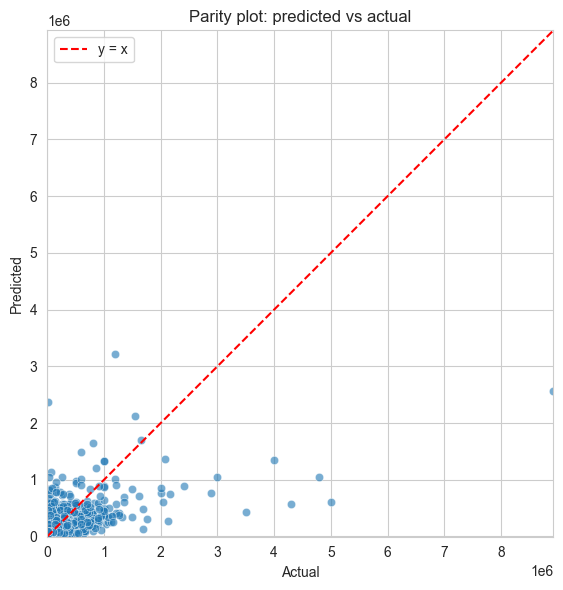

In [384]:
# Visualization: parity plot (predicted vs actual)
comparison = pd.DataFrame({
    "actual": y_test,
    "pred": best_xgb_pred,
})

plt.figure(figsize=(6, 6))
sns.scatterplot(data=comparison, x="actual", y="pred", alpha=0.6)
lims = [comparison.values.min(), comparison.values.max()]
plt.plot(lims, lims, "r--", label="y = x")
plt.xlim(lims)
plt.ylim(lims)
plt.gca().set_aspect('equal', 'box')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Parity plot: predicted vs actual")
plt.legend()
plt.tight_layout()
plt.show()

My model underestimates small subsidies and overestimates large ones.

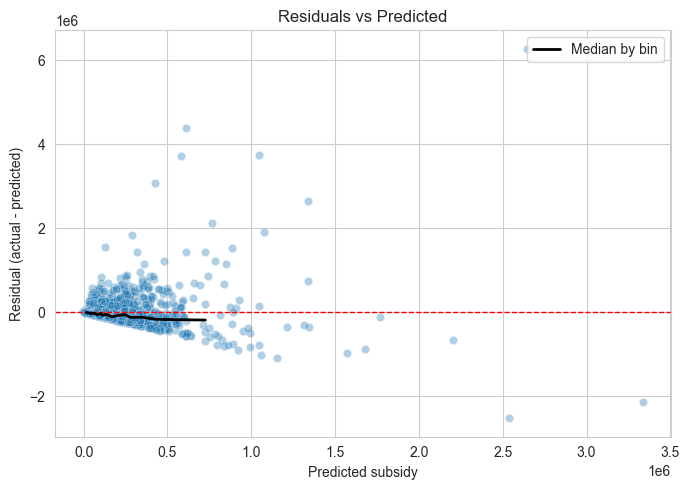

In [399]:
# Residual diagnostics: residuals vs predicted and key features
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Build diagnostics DataFrame
pred_series = pd.Series(best_xgb_pred, index=X_test.index, name="pred")
residuals = y_test.astype("float64") - pred_series.astype("float64")

diag_df = pd.DataFrame({
    "actual": y_test.values,
    "pred": pred_series.values,
    "residual": residuals.values,
}, index=X_test.index)

sns.set_style("whitegrid")

# 2) Residuals vs Predicted
plt.figure(figsize=(7, 5))
sns.scatterplot(x=diag_df["pred"], y=diag_df["residual"], alpha=0.35)
plt.axhline(0, color="red", linestyle="--", linewidth=1)
# Add a simple binned-median trend line
quantiles = np.linspace(0, 1, 21)
edges = np.quantile(diag_df["pred"], quantiles)
centers, meds = [], []
for i in range(len(edges) - 1):
    m = (diag_df["pred"] >= edges[i]) & (diag_df["pred"] < edges[i + 1])
    if m.any():
        centers.append(np.median(diag_df.loc[m, "pred"]))
        meds.append(np.median(diag_df.loc[m, "residual"]))
if centers:
    plt.plot(centers, meds, color="black", linewidth=2, label="Median by bin")
plt.title("Residuals vs Predicted")
plt.xlabel("Predicted subsidy")
plt.ylabel("Residual (actual - predicted)")
plt.legend()
plt.tight_layout()
plt.show()

In [400]:
### Feature importance plot for XGB model
xgb_model_final = best_xgb_clf.named_steps['model']
feature_importances = xgb_model_final.feature_importances_
feature_names = best_xgb_clf.named_steps['prep'].get_feature_names_out()  

/var/folders/4t/1cnp1cq57sscygp0x865kkj80000gn/T/ipykernel_47921/2072130679.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df.head(30), x='Importance', y='Feature', palette='viridis')


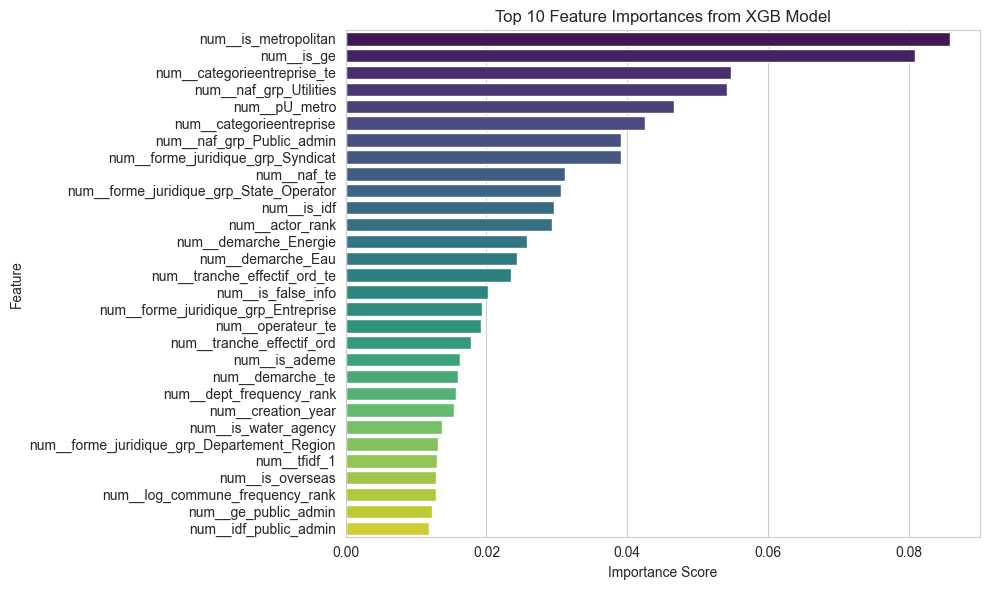

In [402]:
# visualize feature importances
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
})  .sort_values(by='Importance', ascending=False) 
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(30), x='Importance', y='Feature', palette='viridis')
plt.title('Top 10 Feature Importances from XGB Model')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### double regressor pipeline (possible solution)

In [ ]:
# I will train a classifier on the training data to predict whether subsidies exceed
# an 80th percentile threshold, then add this binary prediction as an engineered feature
# to both training and test sets for the final regression model

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.impute import SimpleImputer

# 1) Define threshold at 80th percentile
threshold_80 = np.percentile(y_train, 80)
print(f"80th percentile threshold: {threshold_80:,.0f}")

# 2) Create binary target for training
y_train_high = (y_train >= threshold_80).astype(int)
print(f"High subsidy cases in train: {y_train_high.sum()} / {len(y_train_high)} ({y_train_high.mean():.2%})")

# 3) Create preprocessing pipeline with imputation
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

preprocess_clf = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
], remainder="passthrough")

# 4) Train classifier
clf_high = Pipeline([
    ("prep", preprocess_clf),
    ("model", GradientBoostingClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.8,
        random_state=42
    ))
])

clf_high.fit(X_train, y_train_high)

# 5) Predict on test data
y_test_high_pred = clf_high.predict(X_test)
y_test_high_proba = clf_high.predict_proba(X_test)[:, 1]

# 6) Evaluate classifier
y_test_high_actual = (y_test >= threshold_80).astype(int)
print(f"\nHigh subsidy cases in test: {y_test_high_actual.sum()} / {len(y_test_high_actual)} ({y_test_high_actual.mean():.2%})")
print(f"ROC-AUC Score: {roc_auc_score(y_test_high_actual, y_test_high_proba):.4f}")

# 7) Add predicted flag as feature to train/test
X_train_augmented = X_train.copy()
X_train_augmented['high_subsidy_flag'] = clf_high.predict(X_train)

X_test_augmented = X_test.copy()
X_test_augmented['high_subsidy_flag'] = y_test_high_pred

print("\nAugmented feature sets created with 'high_subsidy_flag'")
print(f"X_train_augmented shape: {X_train_augmented.shape}")
print(f"X_test_augmented shape: {X_test_augmented.shape}")

80th percentile threshold: 263,361
High subsidy cases in train: 1419 / 7094 (20.00%)

High subsidy cases in test: 346 / 1774 (19.50%)
ROC-AUC Score: 0.8395

Augmented feature sets created with 'high_subsidy_flag'
X_train_augmented shape: (7094, 53)
X_test_augmented shape: (1774, 53)


In [266]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    tree_method="hist",
    n_estimators=800,
    n_jobs=-1,
    enable_categorical=True,
    #verbosity=1,
)

xgb_clf = Pipeline([
    ("prep", preprocess),
    ("model", xgb_model),
])

# Compact grid to keep runtime reasonable
xgb_param_grid = {
    "model__learning_rate": [0.003, 0.005, 0.0055, 0.0058],
    "model__max_depth": [7, 8],
    "model__min_child_weight": [5],
    "model__subsample": [0.7, 0.8],
    "model__colsample_bytree": [0.75, 0.7],
    "model__gamma": [0, 0.1],
    "model__reg_alpha": [0.5, 0.7],
    "model__reg_lambda": [5, 6],
}

xgb_search = GridSearchCV(
    estimator=xgb_clf,
    param_grid=xgb_param_grid,
    n_jobs=-1,
    cv=5,
    scoring="r2",
    verbose=1,
)

xgb_search.fit(X_train_augmented, y_train)

print("XGB best params:", xgb_search.best_params_)
print(f"XGB CV best R²: {xgb_search.best_score_:.4f}")

best_xgb_clf = xgb_search.best_estimator_
best_xgb_pred = best_xgb_clf.predict(X_test_augmented)

xgb_r2 = r2_score(y_test.astype('float64'), best_xgb_pred.astype('float64'))
print(f"XGB test R²: {xgb_r2:.4f}")

Fitting 5 folds for each of 256 candidates, totalling 1280 fits
XGB best params: {'model__colsample_bytree': 0.7, 'model__gamma': 0, 'model__learning_rate': 0.0055, 'model__max_depth': 7, 'model__min_child_weight': 5, 'model__reg_alpha': 0.5, 'model__reg_lambda': 6, 'model__subsample': 0.7}
XGB CV best R²: 0.3580
XGB test R²: 0.3011
